# Token Pooling in Vision Transformers — Small-Scale Reproduction

This notebook is a Kaggle-ready small-scale reproduction inspired by **Token Pooling in Vision Transformers**.  
It compares a baseline tiny ViT against a pooled ViT on **CIFAR-10** and saves figures and a ZIP bundle of outputs.


In [1]:
import os
import time
import math
import json
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

OUT_DIR = Path("outputs_token_pooling")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("device:", device)


device: cpu


## Configuration


In [2]:
CFG = {
    "image_size": 32,
    "num_classes": 10,
    "batch_size": 256 if device.type == "cuda" else 128,
    "epochs": 8,
    "lr": 3e-4,
    "weight_decay": 5e-2,
    "num_workers": 2 if device.type == "cuda" else 0,
    "train_subset": None,
    "val_ratio": 0.1,
    "baseline": {
        "name": "vit_tiny_baseline",
        "patch_size": 4,
        "dim": 128,
        "depth": 6,
        "heads": 4,
        "mlp_ratio": 4.0,
        "dropout": 0.1,
        "pool_layer": None,
        "pool_tokens": None,
    },
    "pooled": {
        "name": "vit_tiny_token_pool",
        "patch_size": 4,
        "dim": 128,
        "depth": 6,
        "heads": 4,
        "mlp_ratio": 4.0,
        "dropout": 0.1,
        "pool_layer": 2,
        "pool_tokens": 16,
    },
}
print(json.dumps(CFG, indent=2))


{
  "image_size": 32,
  "num_classes": 10,
  "batch_size": 128,
  "epochs": 8,
  "lr": 0.0003,
  "weight_decay": 0.05,
  "num_workers": 0,
  "train_subset": null,
  "val_ratio": 0.1,
  "baseline": {
    "name": "vit_tiny_baseline",
    "patch_size": 4,
    "dim": 128,
    "depth": 6,
    "heads": 4,
    "mlp_ratio": 4.0,
    "dropout": 0.1,
    "pool_layer": null,
    "pool_tokens": null
  },
  "pooled": {
    "name": "vit_tiny_token_pool",
    "patch_size": 4,
    "dim": 128,
    "depth": 6,
    "heads": 4,
    "mlp_ratio": 4.0,
    "dropout": 0.1,
    "pool_layer": 2,
    "pool_tokens": 16
  }
}


## Helpers


In [3]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def accuracy_top1(logits, targets):
    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()

def savefig(path):
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.close()

def show_images_grid(images, titles=None, ncols=6, figsize=(10, 6)):
    images = images.detach().cpu()
    n = images.shape[0]
    nrows = math.ceil(n / ncols)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(nrows, ncols, i + 1)
        img = images[i].permute(1, 2, 0).clamp(0, 1).numpy()
        plt.imshow(img)
        plt.axis("off")
        if titles is not None:
            plt.title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()
    plt.close()

def confusion_matrix_torch(y_true, y_pred, num_classes):
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    for t, p in zip(y_true, y_pred):
        cm[t.long(), p.long()] += 1
    return cm

def plot_confusion(cm, class_names, path):
    cm = cm.float()
    cm = cm / cm.sum(dim=1, keepdim=True).clamp_min(1)
    plt.figure(figsize=(8, 7))
    plt.imshow(cm.numpy(), cmap="Blues")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
    plt.yticks(range(len(class_names)), class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    savefig(path)

def make_zip(zip_path, folder):
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in Path(folder).rglob("*"):
            if p.is_file():
                zf.write(p, arcname=str(p.relative_to(folder.parent)))

def estimate_attention_ops(seq_lens, dim, heads):
    total = 0
    for n in seq_lens:
        total += heads * (n * n) + 4 * n * dim * dim
    return int(total)

def estimate_attn_mem_mb(seq_lens, batch_size, heads, dtype_bytes=2):
    total_bytes = 0
    for n in seq_lens:
        total_bytes += batch_size * heads * n * n * dtype_bytes
    return total_bytes / (1024 ** 2)

class Timer:
    def __init__(self):
        self.start = time.time()
    def elapsed(self):
        return time.time() - self.start
    def pretty(self):
        sec = int(self.elapsed())
        m, s = divmod(sec, 60)
        h, m = divmod(m, 60)
        if h > 0:
            return f"{h}h {m}m {s}s"
        return f"{m}m {s}s"


## Data


100%|██████████| 170M/170M [00:07<00:00, 23.0MB/s]


train: 45000 val: 5000 test: 10000


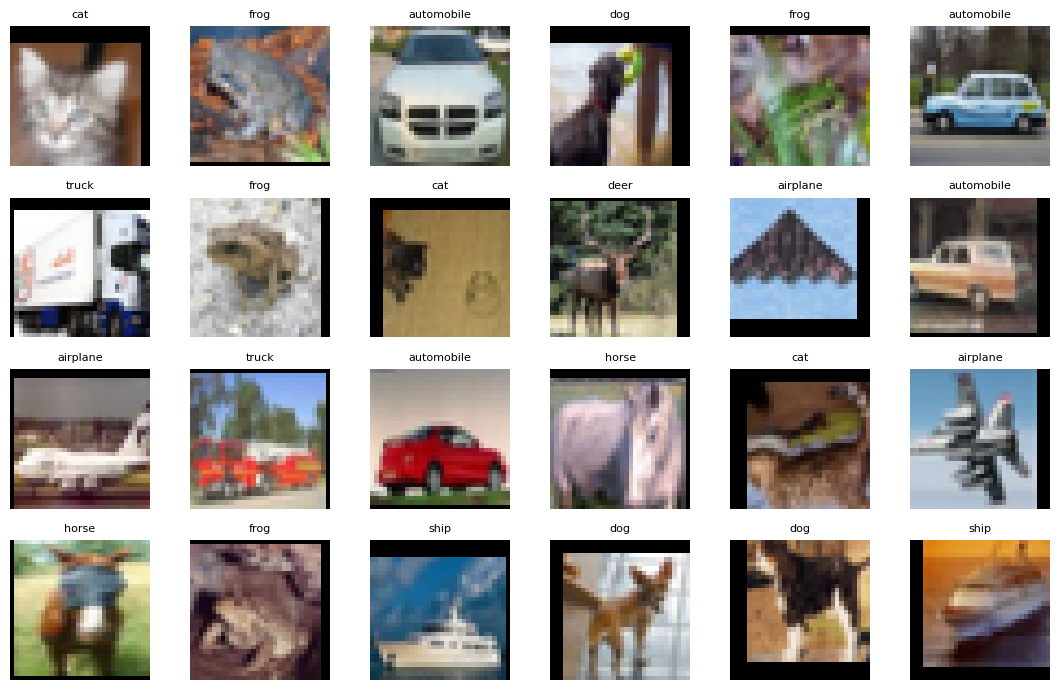

In [4]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=train_tf)
test_set = datasets.CIFAR10(root="data", train=False, download=True, transform=test_tf)

val_size = int(len(train_full) * CFG["val_ratio"])
train_size = len(train_full) - val_size
train_set, val_set = random_split(train_full, [train_size, val_size], generator=torch.Generator().manual_seed(SEED))

val_set.dataset = datasets.CIFAR10(root="data", train=True, download=False, transform=test_tf)
train_set.dataset = datasets.CIFAR10(root="data", train=True, download=False, transform=train_tf)

if CFG["train_subset"] is not None:
    idx = list(range(min(CFG["train_subset"], len(train_set))))
    train_set = torch.utils.data.Subset(train_set, idx)

loader_train = DataLoader(train_set, batch_size=CFG["batch_size"], shuffle=True, num_workers=CFG["num_workers"], pin_memory=(device.type=="cuda"))
loader_val = DataLoader(val_set, batch_size=CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"], pin_memory=(device.type=="cuda"))
loader_test = DataLoader(test_set, batch_size=CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"], pin_memory=(device.type=="cuda"))

class_names = train_full.classes

xb, yb = next(iter(loader_train))
xb_vis = xb[:24] * torch.tensor(std).view(1,3,1,1) + torch.tensor(mean).view(1,3,1,1)
print("train:", len(train_set), "val:", len(val_set), "test:", len(test_set))
show_images_grid(xb_vis, titles=[class_names[int(t)] for t in yb[:24]], ncols=6, figsize=(11, 7))


## Model


In [5]:
class PatchEmbed(nn.Module):
    def __init__(self, in_ch=3, dim=128, patch_size=4):
        super().__init__()
        self.patch_size = patch_size
        self.proj = nn.Conv2d(in_ch, dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)
        h, w = x.shape[-2:]
        x = x.flatten(2).transpose(1, 2)
        return x, h, w

class MLP(nn.Module):
    def __init__(self, dim, mlp_ratio=4.0, drop=0.0):
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x

class MHSA(nn.Module):
    def __init__(self, dim, heads=4, drop=0.0):
        super().__init__()
        self.dim = dim
        self.heads = heads
        self.head_dim = dim // heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        b, n, c = x.shape
        qkv = self.qkv(x).reshape(b, n, 3, self.heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        out = attn @ v
        out = out.transpose(1, 2).reshape(b, n, c)
        out = self.proj(out)
        out = self.drop(out)
        return out, attn

class Block(nn.Module):
    def __init__(self, dim, heads, mlp_ratio, drop):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = MHSA(dim, heads=heads, drop=drop)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = MLP(dim, mlp_ratio=mlp_ratio, drop=drop)

    def forward(self, x):
        y, attn = self.attn(self.norm1(x))
        x = x + y
        x = x + self.mlp(self.norm2(x))
        return x, attn

class TokenPool(nn.Module):
    def __init__(self, dim, out_tokens):
        super().__init__()
        self.out_tokens = out_tokens
        self.norm = nn.LayerNorm(dim)
        self.assign = nn.Linear(dim, out_tokens)

    def forward(self, x):
        cls_tok = x[:, :1]
        tok = x[:, 1:]
        tok_norm = self.norm(tok)
        logits = self.assign(tok_norm)
        weights = logits.softmax(dim=-1)
        denom = weights.sum(dim=1, keepdim=True).transpose(1, 2).clamp_min(1e-6)
        pooled = torch.einsum("bnk,bnd->bkd", weights, tok) / denom
        x = torch.cat([cls_tok, pooled], dim=1)
        return x, weights

class MiniViT(nn.Module):
    def __init__(self, image_size=32, patch_size=4, num_classes=10, dim=128, depth=6, heads=4, mlp_ratio=4.0, dropout=0.1, pool_layer=None, pool_tokens=None):
        super().__init__()
        self.patch = PatchEmbed(3, dim, patch_size)
        num_patches = (image_size // patch_size) ** 2
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + num_patches, dim))
        self.pos_drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(dim, heads, mlp_ratio, dropout) for _ in range(depth)])
        self.pool_layer = pool_layer
        self.token_pool = TokenPool(dim, pool_tokens) if pool_layer is not None and pool_tokens is not None else None
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.head.weight, std=0.02)
        nn.init.zeros_(self.head.bias)

    def forward_features(self, x, return_info=False):
        x, h, w = self.patch(x)
        b, n, c = x.shape
        cls_tok = self.cls_token.expand(b, -1, -1)
        x = torch.cat([cls_tok, x], dim=1)
        x = x + self.pos_embed[:, :x.shape[1]]
        x = self.pos_drop(x)
        seq_lens = [x.shape[1]]
        attn_maps = []
        assign_map = None
        for i, blk in enumerate(self.blocks):
            x, attn = blk(x)
            attn_maps.append(attn)
            if self.token_pool is not None and i == self.pool_layer:
                x, assign_map = self.token_pool(x)
                seq_lens.append(x.shape[1])
            else:
                seq_lens.append(x.shape[1])
        x = self.norm(x)
        cls = x[:, 0]
        if return_info:
            return cls, {"seq_lens": seq_lens, "assign_map": assign_map, "attn_maps": attn_maps}
        return cls

    def forward(self, x, return_info=False):
        if return_info:
            cls, info = self.forward_features(x, return_info=True)
            return self.head(cls), info
        cls = self.forward_features(x, return_info=False)
        return self.head(cls)


## Training and evaluation


In [6]:
def train_one_epoch(model, loader, optimizer, scaler, criterion):
    model.train()
    loss_sum = 0.0
    acc_sum = 0.0
    n_items = 0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=(device.type=="cuda")):
            logits = model(x)
            loss = criterion(logits, y)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        bs = x.size(0)
        loss_sum += loss.item() * bs
        acc_sum += accuracy_top1(logits.detach(), y) * bs
        n_items += bs
    return loss_sum / n_items, acc_sum / n_items

@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    loss_sum = 0.0
    acc_sum = 0.0
    n_items = 0
    all_true, all_pred = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=(device.type=="cuda")):
            logits = model(x)
            loss = criterion(logits, y) if criterion is not None else None
        bs = x.size(0)
        if loss is not None:
            loss_sum += loss.item() * bs
        acc_sum += accuracy_top1(logits, y) * bs
        n_items += bs
        all_true.append(y.cpu())
        all_pred.append(logits.argmax(dim=1).cpu())
    out = {"acc": acc_sum / n_items, "y_true": torch.cat(all_true), "y_pred": torch.cat(all_pred)}
    if criterion is not None:
        out["loss"] = loss_sum / n_items
    return out

def run_experiment(cfg):
    model = MiniViT(
        image_size=CFG["image_size"],
        patch_size=cfg["patch_size"],
        num_classes=CFG["num_classes"],
        dim=cfg["dim"],
        depth=cfg["depth"],
        heads=cfg["heads"],
        mlp_ratio=cfg["mlp_ratio"],
        dropout=cfg["dropout"],
        pool_layer=cfg["pool_layer"],
        pool_tokens=cfg["pool_tokens"],
    ).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type=="cuda"))
    hist = []
    best_acc = -1.0
    best_path = OUT_DIR / f"{cfg['name']}.pt"
    total_timer = Timer()

    dummy = torch.randn(1, 3, CFG["image_size"], CFG["image_size"], device=device)
    with torch.no_grad():
        _, info = model(dummy, return_info=True)
    seq_lens = info["seq_lens"]
    approx_ops = estimate_attention_ops(seq_lens, cfg["dim"], cfg["heads"])
    attn_mem_mb = estimate_attn_mem_mb(seq_lens, CFG["batch_size"], cfg["heads"])

    print(f"Approx runtime for {cfg['name']} on {device.type}: {CFG['epochs']} epochs")
    print("seq_lens:", seq_lens, "| approx_ops:", approx_ops, "| attn_mem_mb:", round(attn_mem_mb, 2))

    for epoch in range(CFG["epochs"]):
        et = Timer()
        tr_loss, tr_acc = train_one_epoch(model, loader_train, optimizer, scaler, criterion)
        va = evaluate(model, loader_val, criterion)
        scheduler.step()
        row = {"epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va["loss"], "val_acc": va["acc"], "epoch_time_sec": et.elapsed()}
        hist.append(row)
        eta = (CFG["epochs"] - epoch - 1) * row["epoch_time_sec"]
        print(f"[{cfg['name']}] epoch {epoch+1:02d}/{CFG['epochs']} | train_acc={tr_acc:.4f} val_acc={va['acc']:.4f} | epoch_time={int(row['epoch_time_sec']//60)}m {int(row['epoch_time_sec']%60)}s | eta={int(eta//60)}m {int(eta%60)}s")
        if va["acc"] > best_acc:
            best_acc = va["acc"]
            torch.save(model.state_dict(), best_path)

    model.load_state_dict(torch.load(best_path, map_location=device))
    val_best = evaluate(model, loader_val, criterion)
    test_out = evaluate(model, loader_test, criterion)
    result = {
        "name": cfg["name"],
        "config": cfg,
        "params": count_parameters(model),
        "seq_lens": seq_lens,
        "approx_ops": approx_ops,
        "attn_mem_mb": attn_mem_mb,
        "history": hist,
        "best_weight_path": str(best_path),
        "best_val_acc": val_best["acc"],
        "test_acc": test_out["acc"],
        "test_y_true": test_out["y_true"],
        "test_y_pred": test_out["y_pred"],
        "total_time_sec": total_timer.elapsed(),
    }
    print(f"[{cfg['name']}] total elapsed: {int(result['total_time_sec']//60)}m {int(result['total_time_sec']%60)}s")
    return result


## Run baseline and pooled models


In [7]:
results = []
for model_cfg in [CFG["baseline"], CFG["pooled"]]:
    results.append(run_experiment(model_cfg))


/tmp/ipykernel_17/4034686581.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type=="cuda"))


Approx runtime for vit_tiny_baseline on cpu: 8 epochs
seq_lens: [65, 65, 65, 65, 65, 65, 65] | approx_ops: 29937180 | attn_mem_mb: 28.88


/tmp/ipykernel_17/4034686581.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type=="cuda")):
/tmp/ipykernel_17/4034686581.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type=="cuda")):


[vit_tiny_baseline] epoch 01/8 | train_acc=0.3248 val_acc=0.4026 | epoch_time=8m 46s | eta=61m 25s
[vit_tiny_baseline] epoch 02/8 | train_acc=0.4423 val_acc=0.4892 | epoch_time=8m 39s | eta=51m 57s
[vit_tiny_baseline] epoch 03/8 | train_acc=0.5017 val_acc=0.5074 | epoch_time=8m 31s | eta=42m 35s
[vit_tiny_baseline] epoch 04/8 | train_acc=0.5359 val_acc=0.5670 | epoch_time=8m 32s | eta=34m 8s
[vit_tiny_baseline] epoch 05/8 | train_acc=0.5636 val_acc=0.5838 | epoch_time=8m 27s | eta=25m 21s
[vit_tiny_baseline] epoch 06/8 | train_acc=0.5840 val_acc=0.5984 | epoch_time=8m 32s | eta=17m 5s
[vit_tiny_baseline] epoch 07/8 | train_acc=0.6035 val_acc=0.6260 | epoch_time=8m 37s | eta=8m 37s
[vit_tiny_baseline] epoch 08/8 | train_acc=0.6119 val_acc=0.6296 | epoch_time=8m 30s | eta=0m 0s
[vit_tiny_baseline] total elapsed: 69m 11s
Approx runtime for vit_tiny_token_pool on cpu: 8 epochs
seq_lens: [65, 65, 65, 17, 17, 17, 17] | approx_ops: 17291292 | attn_mem_mb: 13.51
[vit_tiny_token_pool] epoch 01/

## Curves and comparison


In [8]:
def plot_curves(results, path):
    plt.figure(figsize=(9, 5))
    for r in results:
        hist = pd.DataFrame(r["history"])
        plt.plot(hist["epoch"], hist["val_acc"], marker="o", label=f"{r['name']} val")
        plt.plot(hist["epoch"], hist["train_acc"], linestyle="--", alpha=0.6, label=f"{r['name']} train")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)
    savefig(path)

def plot_compare(results, path):
    names = [r["name"] for r in results]
    test_acc = [r["test_acc"] for r in results]
    ops = [r["approx_ops"]/1e6 for r in results]
    times = [r["total_time_sec"]/60 for r in results]
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.bar(names, test_acc)
    plt.ylabel("Test accuracy")
    plt.xticks(rotation=15)
    plt.subplot(1, 3, 2)
    plt.bar(names, ops)
    plt.ylabel("Approx attention proxy (M)")
    plt.xticks(rotation=15)
    plt.subplot(1, 3, 3)
    plt.bar(names, times)
    plt.ylabel("Train time (min)")
    plt.xticks(rotation=15)
    savefig(path)

def plot_token_counts(results, path):
    plt.figure(figsize=(8, 4))
    for r in results:
        plt.plot(range(len(r["seq_lens"])), r["seq_lens"], marker="o", label=r["name"])
    plt.xlabel("Stage")
    plt.ylabel("Sequence length")
    plt.legend()
    plt.grid(alpha=0.3)
    savefig(path)

plot_curves(results, OUT_DIR / "training_curves.png")
plot_compare(results, OUT_DIR / "comparison.png")
plot_token_counts(results, OUT_DIR / "token_counts.png")
print("saved plots")


saved plots


## Confusion matrices


In [9]:
for r in results:
    cm = confusion_matrix_torch(r["test_y_true"], r["test_y_pred"], CFG["num_classes"])
    plot_confusion(cm, class_names, OUT_DIR / f"confusion_{r['name']}.png")
print("saved confusion matrices")


saved confusion matrices


## Pooling behavior visualization


In [10]:
pooled_result = [r for r in results if "token_pool" in r["name"]][0]
pooled_cfg = pooled_result["config"]

pooled_model = MiniViT(
    image_size=CFG["image_size"],
    patch_size=pooled_cfg["patch_size"],
    num_classes=CFG["num_classes"],
    dim=pooled_cfg["dim"],
    depth=pooled_cfg["depth"],
    heads=pooled_cfg["heads"],
    mlp_ratio=pooled_cfg["mlp_ratio"],
    dropout=pooled_cfg["dropout"],
    pool_layer=pooled_cfg["pool_layer"],
    pool_tokens=pooled_cfg["pool_tokens"],
).to(device)
pooled_model.load_state_dict(torch.load(pooled_result["best_weight_path"], map_location=device))
pooled_model.eval()

x_vis, y_vis = next(iter(loader_test))
x_in = x_vis[:1].to(device)
with torch.no_grad():
    logits, info = pooled_model(x_in, return_info=True)

assign = info["assign_map"][0].cpu()
cluster_id = assign.argmax(dim=1)
grid = int(math.sqrt(assign.shape[0]))
cluster_img = cluster_id.view(grid, grid).numpy()

img = x_vis[0] * torch.tensor(std).view(3,1,1) + torch.tensor(mean).view(3,1,1)
img = img.permute(1,2,0).clamp(0,1).numpy()

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(f"Input | true={class_names[int(y_vis[0])]}")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cluster_img, cmap="tab20")
plt.title("Dominant pooled token id")
plt.axis("off")
savefig(OUT_DIR / "pooling_assignment_example.png")
print("saved pooling behavior example")


saved pooling behavior example


## Summary table


In [11]:
rows = []
for r in results:
    rows.append({
        "model": r["name"],
        "params_m": round(r["params"]/1e6, 3),
        "seq_lens": str(r["seq_lens"]),
        "approx_ops_m": round(r["approx_ops"]/1e6, 2),
        "attn_mem_mb": round(r["attn_mem_mb"], 2),
        "best_val_acc": round(r["best_val_acc"], 4),
        "test_acc": round(r["test_acc"], 4),
        "train_time_min": round(r["total_time_sec"]/60, 2),
    })
summary_df = pd.DataFrame(rows)
display(summary_df)
summary_df.to_csv(OUT_DIR / "summary.csv", index=False)


,model,params_m,seq_lens,approx_ops_m,attn_mem_mb,best_val_acc,test_acc,train_time_min
0,vit_tiny_baseline,1.206,"[65, 65, 65, 65, 65, 65, 65]",29.94,28.88,0.6296,0.6227,69.19
1,vit_tiny_token_pool,1.208,"[65, 65, 65, 17, 17, 17, 17]",17.29,13.51,0.6110,0.6022,46.87


## ZIP export


In [12]:
zip_path = OUT_DIR.parent / "token_pooling_project_outputs.zip"
make_zip(zip_path, OUT_DIR)
print("saved:", zip_path)


saved: token_pooling_project_outputs.zip
